## BERT : Bi-directional Encoder Representations from Transformers

* BERT Base : 110 million parameters
* BERT Large : 340 million parameters

- I buy apple products , which [are] reliable in the market

In [59]:
from transformers import BertForQuestionAnswering, RobertaTokenizer, RobertaModel
from transformers import BertTokenizer
import torch

In [34]:
model_name = "google-bert/bert-large-uncased-whole-word-masking-finetuned-squad"

model = BertForQuestionAnswering.from_pretrained(model_name)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForQuestionAnswering LOAD REPORT from: google-bert/bert-large-uncased-whole-word-masking-finetuned-squad
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [3]:
tokenizer = BertTokenizer.from_pretrained(model_name)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [4]:
question = " What is the full form of DVD"
answer_document = " The first DVD (Digital Versatile Disc) was released on March 24, 1997"

In [5]:
encoding  = tokenizer(text=question,text_pair=answer_document)
print(encoding)

{'input_ids': [101, 2054, 2003, 1996, 2440, 2433, 1997, 4966, 102, 1996, 2034, 4966, 1006, 3617, 22979, 5860, 1007, 2001, 2207, 2006, 2233, 2484, 1010, 2722, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [6]:
inputs = encoding['input_ids']
sentence_embedding = encoding['token_type_ids']
tokens = tokenizer.convert_ids_to_tokens(inputs)

In [7]:
output = model(input_ids = torch.tensor([inputs]),token_type_ids=torch.tensor([sentence_embedding]))

In [8]:
output

QuestionAnsweringModelOutput(loss=None, start_logits=tensor([[-5.7414, -3.9613, -7.4169, -5.5901, -6.5304, -7.3308, -8.2032, -8.7703,
         -5.7414,  1.4903, -0.4001,  3.3462,  0.4573,  6.0122, -0.1871, -2.4875,
         -4.3522, -5.4022, -4.4505, -5.6878, -3.7313, -5.4402, -6.6229, -2.1775,
         -5.7412]], grad_fn=<CloneBackward0>), end_logits=tensor([[-0.6534, -2.9410, -5.2168, -6.0529, -6.8325, -6.1988, -6.6742, -6.9263,
         -0.6532, -4.0703, -3.0261,  3.5199, -3.4243, -1.4442, -1.0155,  6.6673,
          3.6648, -4.0518, -2.8051, -5.0573, -4.6587, -4.0428, -3.6459, -1.4052,
         -0.6542]], grad_fn=<CloneBackward0>), hidden_states=None, attentions=None)

In [9]:
start_index = torch.argmax(output.start_logits)
end_index = torch.argmax(output.end_logits)

print(start_index, end_index)

tensor(13) tensor(15)


In [10]:
answer = ' '.join(tokens[start_index:end_index+1])
print(answer)

digital versatile disc


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
s_scores = output.start_logits.detach().numpy().flatten()
e_scores = output.end_logits.detach().numpy().flatten()

In [13]:
token_labels = []

for i, tok in enumerate(tokens):
  token_labels.append("{:} - {:>2}".format(tok,i))

In [14]:
token_labels

['[CLS] -  0',
 'what -  1',
 'is -  2',
 'the -  3',
 'full -  4',
 'form -  5',
 'of -  6',
 'dvd -  7',
 '[SEP] -  8',
 'the -  9',
 'first - 10',
 'dvd - 11',
 '( - 12',
 'digital - 13',
 'versatile - 14',
 'disc - 15',
 ') - 16',
 'was - 17',
 'released - 18',
 'on - 19',
 'march - 20',
 '24 - 21',
 ', - 22',
 '1997 - 23',
 '[SEP] - 24']

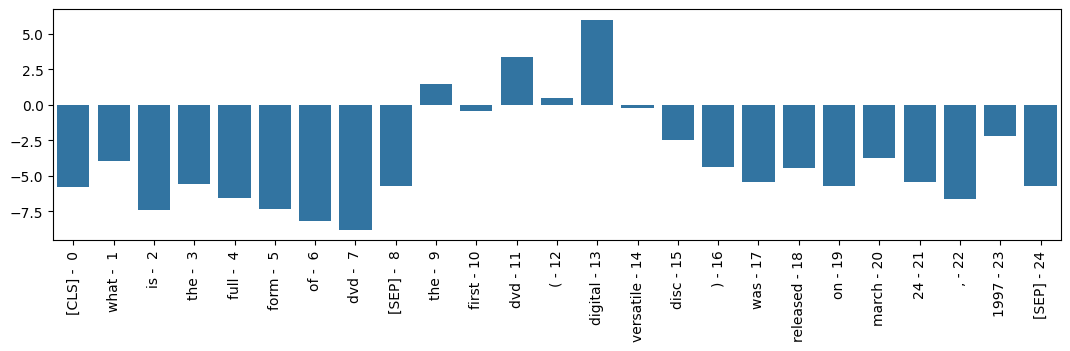

In [15]:
plt.figure(figsize=(13,3))
ax = sns.barplot(x=token_labels,y=s_scores)
plt.xticks(rotation=90)
plt.show()

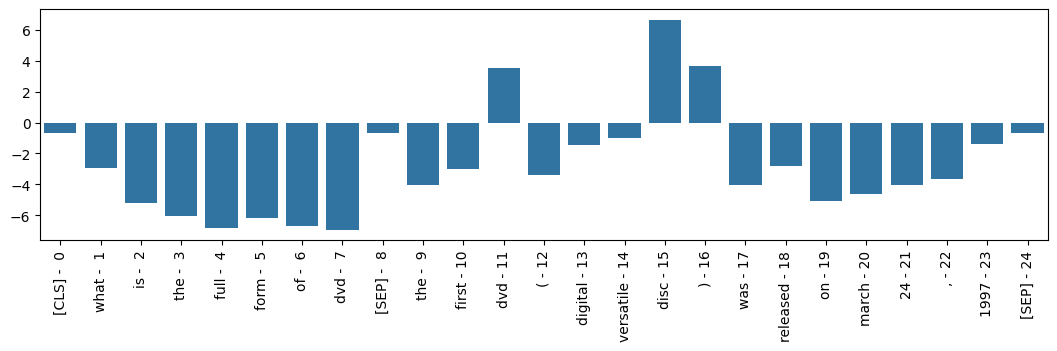

In [16]:
plt.figure(figsize=(13,3))
ax = sns.barplot(x=token_labels,y=e_scores)
plt.xticks(rotation=90)
plt.show()

ChatBot

In [45]:
tata_motors_context = '''

Established in 1945 as Tata Engineering and Locomotive Company (TELCO), Tata Motors began as a manufacturer of steam locomotives before shifting to commercial vehicles in 1954 via a collaboration with Daimler-Benz. Over the decades, it expanded into indigenous SUVs, passenger cars, and global luxury brands like Jaguar Land Rover.

'''

In [51]:
print(tata_motors_context)



Established in 1945 as Tata Engineering and Locomotive Company (TELCO), Tata Motors began as a manufacturer of steam locomotives before shifting to commercial vehicles in 1954 via a collaboration with Daimler-Benz. Over the decades, it expanded into indigenous SUVs, passenger cars, and global luxury brands like Jaguar Land Rover.




In [56]:
def faq_bot(question):
  input_ids = tokenizer.encode(question,tata_motors_context)
  tokens = tokenizer.convert_ids_to_tokens(input_ids)
  sep_idx = input_ids.index(tokenizer.sep_token_id)
  num_seg_a = sep_idx+1
  num_seg_b = len(input_ids)-num_seg_a
  segment_ids = [0]*num_seg_a+[1]*num_seg_b

  output = model(torch.tensor([input_ids]), token_type_ids=torch.tensor([segment_ids]))
  answer_s = torch.argmax(output.start_logits)
  answer_e = torch.argmax(output.end_logits)

  if answer_e >= answer_s:
    answer = ' '.join(tokens[answer_s:answer_e+1])
  else:
    return "I do  not have answer of this Question"



  corrected_answer = ''
  for w in answer.split():
    if w[:2] == '##':
      corrected_answer += w[2:]
    else:
      corrected_answer += ' '+ w
  return corrected_answer

  #print(sep_idx)

In [58]:
faq_bot(question='Tell me what is TELCO')

' tata engineering and locomotive company'

# RoBERTa

Robustly Optimised BERT Pre-training Approach

In [60]:
tokenizer = RobertaTokenizer.from_pretrained('FacebookAI/roberta-base')
model = RobertaModel.from_pretrained('FacebookAI/roberta-base')

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [61]:
def faq_bot(question):
  input_ids = tokenizer.encode(question,tata_motors_context)
  tokens = tokenizer.convert_ids_to_tokens(input_ids)
  sep_idx = input_ids.index(tokenizer.sep_token_id)
  num_seg_a = sep_idx+1
  num_seg_b = len(input_ids)-num_seg_a
  segment_ids = [0]*num_seg_a+[1]*num_seg_b

  output = model(torch.tensor([input_ids]), token_type_ids=torch.tensor([segment_ids]))
  answer_s = torch.argmax(output.start_logits)
  answer_e = torch.argmax(output.end_logits)

  if answer_e >= answer_s:
    answer = ' '.join(tokens[answer_s:answer_e+1])
  else:
    return "I do  not have answer of this Question"

In [65]:
import torch
from transformers import AutoModelForQuestionAnswering, AutoTokenizer

# 1. Load model and tokenizer
# Use a SQuAD fine-tuned RoBERTa checkpoint for question answering
MODEL_NAME = "deepset/roberta-base-squad2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForQuestionAnswering.from_pretrained(MODEL_NAME)
model.eval()

def faq_bot(question: str, context: str) -> str:
    # 2. Tokenize without manual segment/token_type_ids
    inputs = tokenizer(
        question,
        context,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    with torch.no_grad():
        outputs = model(**inputs)

    # 3. Extract answer span
    start_idx = torch.argmax(outputs.start_logits)
    end_idx = torch.argmax(outputs.end_logits) + 1

    # Return empty if invalid span or points to <s> / </s>
    if start_idx >= end_idx:
        return "Sorry, I couldn't find an answer."

    # 4. Decode using BPE tokenizer directly
    answer_tokens = inputs["input_ids"][0][start_idx:end_idx]
    answer = tokenizer.decode(answer_tokens, skip_special_tokens=True).strip()

    return answer or "Sorry, I couldn't find an answer."

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [66]:
faq_bot('Tell me Tata motors',
        tata_motors_context)

"Sorry, I couldn't find an answer."